# Square-Cropped Dataset Model Training

The architecture of the model CerealConv was utilised...
https://bsppjournals.onlinelibrary.wiley.com/doi/10.1111/ppa.13684

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint
from collections import Counter
import os
import time

In [2]:
import requests

def send_telegram(msg):
    token = '7343493685:AAHkbAomlTkhvNKVvN_s9xfbOH-3j7kGj10'
    chat_id = '1922507671'
    url = f'https://api.telegram.org/bot{token}/sendMessage'
    requests.post(url, data={'chat_id': chat_id, 'text': msg})

### Import and Dataset Balancing Analysis

Counter({'septoria': 7053, 'yellow_rust': 4388, 'mildew': 2942, 'brown_rust': 2502, 'healthy': 2274})


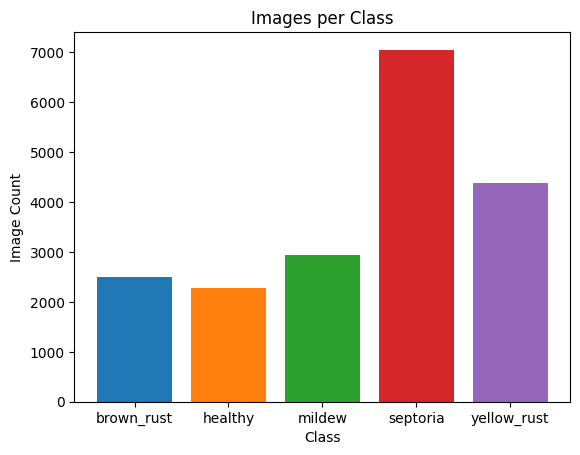

In [3]:
dataset_256_256 = "../../datasets/wheat_dataset/256_256_cropped_wheat_dataset"
dataset_128_128 = "../../datasets/wheat_dataset/128_128_cropped_wheat_dataset"

def count_images_in_classes(path):
    counter = Counter()
    for class_name in os.listdir(path):
        class_path = os.path.join(path, class_name)
        if os.path.isdir(class_path):
            image_files = [f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))]
            counter[class_name] = len(image_files)
    return counter

def display_images_count(counter):
    print(counter)
    classes = list(counter.keys())
    counts = list(counter.values())
    colors = plt.cm.tab10(range(len(classes)))
    plt.bar(classes, counts, color=colors)
    plt.xlabel('Class')
    plt.ylabel('Image Count')
    plt.title('Images per Class')
    plt.show()

counter = count_images_in_classes(dataset_256_256)
display_images_count(counter)


## Splitting, Training and Results Analysis Function

In [ ]:
def build_and_train_model_with_checkpoint(
    dataset_path,
    model_architecture,
    batch_size,
    epochs,
    learning_rate,
    model_name
):
    send_telegram("Model training started. ✅\n Dataset: " + dataset_path + "\n Batch Sizae: " + str(batch_size) + "\n Epochs: " + str(epochs) + "\n Learning Rate: " + str(learning_rate))
    
    img_size = None
    if dataset_path == dataset_128_128:
        img_size = (128, 128)
    elif dataset_path == dataset_256_256:
        img_size = (256, 256)

    train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
        dataset_path,
        image_size=img_size,
        batch_size=batch_size,
        color_mode="rgb",
        validation_split=0.4,
        subset="training",
        seed=42
    )

    val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
        dataset_path,
        image_size=img_size,
        batch_size=batch_size,
        color_mode="rgb",
        validation_split=0.4,
        subset="validation",
        seed=42
    )

    val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
    test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

    class_names = train_dataset.class_names

    AUTOTUNE = tf.data.AUTOTUNE
    train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
    val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)
    test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

    model = model_architecture
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    model.summary()

    checkpoint_file_path = "checkpoint_models/"+model_name+".h5"
    checkpoint = ModelCheckpoint(checkpoint_file_path, monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)

    start_time = time.time()
    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[checkpoint]
    )
    training_time = time.time() - start_time
    print(f"Training Time: {training_time:.2f} seconds")

    # Evaluate final model
    _, test_acc = model.evaluate(test_dataset)
    print(f"Final Model - Test Accuracy: {test_acc:.4f}")

    # Load and evaluate best model
    best_model = tf.keras.models.load_model(checkpoint_file_path)
    _, best_acc = best_model.evaluate(test_dataset)
    print(f"Best Model (val_accuracy) - Test Accuracy: {best_acc:.4f}")

    # Plotting
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Validation")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Validation")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Predictions with final model
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        preds = best_model.predict(images)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    print("Final Model - Classification Report:\n", classification_report(y_true, y_pred, target_names=class_names))
    print("Final Model - Accuracy Score:", accuracy_score(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (Best Model)")
    plt.show()

    # Predictions with best model
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        preds = best_model.predict(images)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    print("Best Model - Classification Report:\n", classification_report(y_true, y_pred, target_names=class_names))
    print("Best Model - Accuracy Score:", accuracy_score(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (Best Model)")
    plt.show()

    send_telegram("Model training completed. ✅\n Dataset: " + dataset_path + str(batch_size) +
                  "\n Epochs: " + str(epochs) + "\n Learning Rate: " + str(learning_rate) +
                  "\n Final Test Accuracy: " + str(test_acc) +
                  "\n Best Test Accuracy: " + str(best_acc) +
                  "\n Training Time: " + str(training_time))

    return best_model

In [ ]:
def build_and_train_model_with_checkpoint_data_augmentation(
    dataset_path,
    model_architecture,
    batch_size,
    epochs,
    learning_rate,
    model_name
):
    send_telegram("Model training started. ✅\n Dataset: " + dataset_path + "\n Batch Sizae: " + str(batch_size) + "\n Epochs: " + str(epochs) + "\n Learning Rate: " + str(learning_rate))
    
    img_size = None
    if dataset_path == dataset_128_128:
        img_size = (128, 128)
    elif dataset_path == dataset_256_256:
        img_size = (256, 256)
    
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1)
    ])

    train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
        dataset_path,
        image_size=img_size,
        batch_size=batch_size,
        color_mode="rgb",
        validation_split=0.4,
        subset="training",
        seed=42
    )
    class_names = train_dataset.class_names
    train_dataset = train_dataset.map(lambda x, y: (data_augmentation(x, training=True), y))

    val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
        dataset_path,
        image_size=img_size,
        batch_size=batch_size,
        color_mode="rgb",
        validation_split=0.4,
        subset="validation",
        seed=42
    )

    val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
    test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

    AUTOTUNE = tf.data.AUTOTUNE
    train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
    val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)
    test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

    model = model_architecture
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    model.summary()

    checkpoint_file_path = "checkpoint_models/"+model_name+".h5"
    checkpoint = ModelCheckpoint(checkpoint_file_path, monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)

    start_time = time.time()
    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[checkpoint]
    )
    training_time = time.time() - start_time
    print(f"Training Time: {training_time:.2f} seconds")

    # Evaluate final model
    _, test_acc = model.evaluate(test_dataset)
    print(f"Final Model - Test Accuracy: {test_acc:.4f}")

    # Load and evaluate best model
    best_model = tf.keras.models.load_model(checkpoint_file_path)
    _, best_acc = best_model.evaluate(test_dataset)
    print(f"Best Model (val_accuracy) - Test Accuracy: {best_acc:.4f}")

    # Plotting
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Validation")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Validation")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Predictions with final model
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        preds = best_model.predict(images)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    print("Final Model - Classification Report:\n", classification_report(y_true, y_pred, target_names=class_names))
    print("Final Model - Accuracy Score:", accuracy_score(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (Best Model)")
    plt.show()

    # Predictions with best model
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        preds = best_model.predict(images)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    print("Best Model - Classification Report:\n", classification_report(y_true, y_pred, target_names=class_names))
    print("Best Model - Accuracy Score:", accuracy_score(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (Best Model)")
    plt.show()

    send_telegram("Model training completed. ✅\n Dataset: " + dataset_path + str(batch_size) +
                  "\n Epochs: " + str(epochs) + "\n Learning Rate: " + str(learning_rate) +
                  "\n Final Test Accuracy: " + str(test_acc) +
                  "\n Best Test Accuracy: " + str(best_acc) +
                  "\n Training Time: " + str(training_time))

    return best_model

# Testing with different Model Architectures

### CerealConv model
Additional Settings (Defeault Settings):
- Image Resolution: 256x256
- Batch_size: 8
- Epochs 75
- Learning_rate 1e-4

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_13 (Conv2D)          (None, 256, 256, 64)      1792      
                                                                 
 batch_normalization_14 (Bat  (None, 256, 256, 64)     256       
 chNormalization)                                                
                                                                 
 conv2d_14 (Conv2D)          (None, 256, 256, 64)      36928     
                                                                 
 batch_normalization_15 (Bat  (None, 256, 256, 64)     256       
 chNormalization)                                                
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 

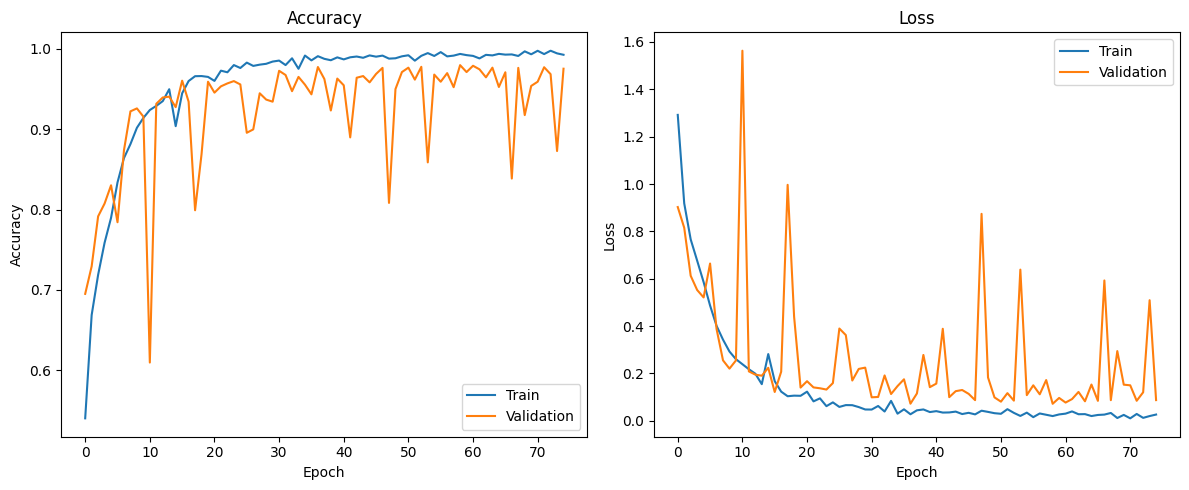

1/1 [==============================] - 0s 24ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       1.00      0.98      0.99       496
     healthy       0.96      0.95      0.95       442
      mildew       0.97      0.97      0.97       600
    septoria       0.98      0.98      0.98      1402
 yellow_rust       0.97      0.99      0.98       891

    accuracy                           0.98      3831
   macro avg       0.98      0.97      0.97      3831
weighted avg       0.98      0.98      0.98      3831

Final Model - Accuracy Score: 0.9767684677629862


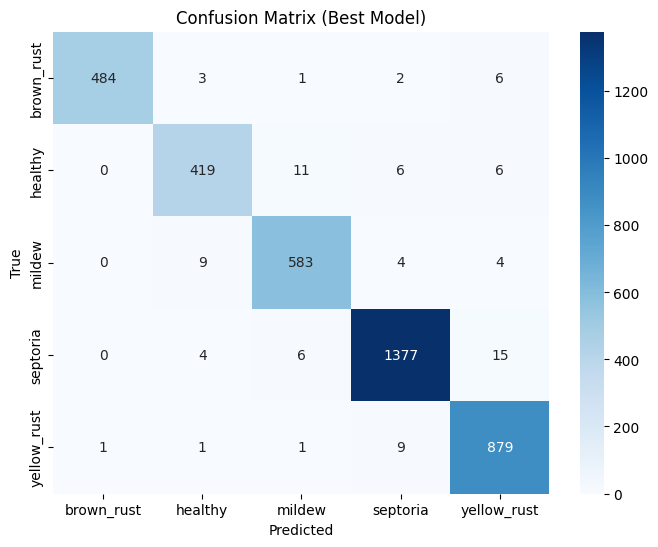

1/1 [==============================] - 0s 21ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       1.00      0.98      0.99       496
     healthy       0.96      0.95      0.95       442
      mildew       0.97      0.97      0.97       604
    septoria       0.98      0.98      0.98      1397
 yellow_rust       0.96      0.99      0.98       892

    accuracy                           0.98      3831
   macro avg       0.98      0.97      0.97      3831
weighted avg       0.98      0.98      0.98      3831

Best Model - Accuracy Score: 0.9762464108587836


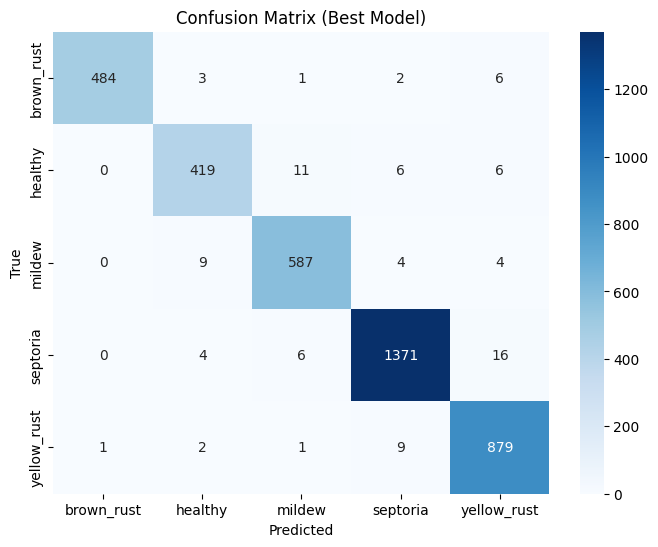

In [6]:
cerealconv_model_checkpoint = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(256, 256, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')

])

build_and_train_model_with_checkpoint(
    dataset_path=dataset_256_256,
    model_architecture=cerealconv_model_checkpoint,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4
)

### CerealConv model
Additional Settings:
- Image Resolution: 128x128
- Batch Size: 8
- Epochs 75
- Learning Rate 1e-4

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 64)      1792      
                                                                 
 batch_normalization (BatchN  (None, 128, 128, 64)     256       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 128, 128, 64)      36928     
                                                                 
 batch_normalization_1 (Batc  (None, 128, 128, 64)     256       
 hNormalization)                                                 
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64

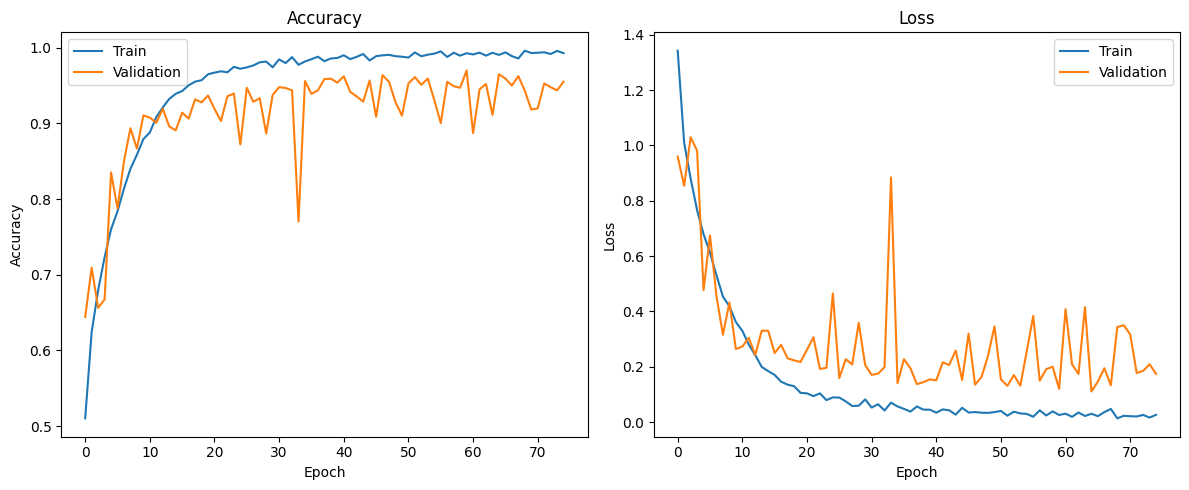

1/1 [==============================] - 0s 20ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.97      0.96      0.96       496
     healthy       0.95      0.93      0.94       442
      mildew       0.96      0.96      0.96       600
    septoria       0.97      0.98      0.98      1402
 yellow_rust       0.95      0.95      0.95       891

    accuracy                           0.96      3831
   macro avg       0.96      0.95      0.96      3831
weighted avg       0.96      0.96      0.96      3831

Final Model - Accuracy Score: 0.9608457321848082


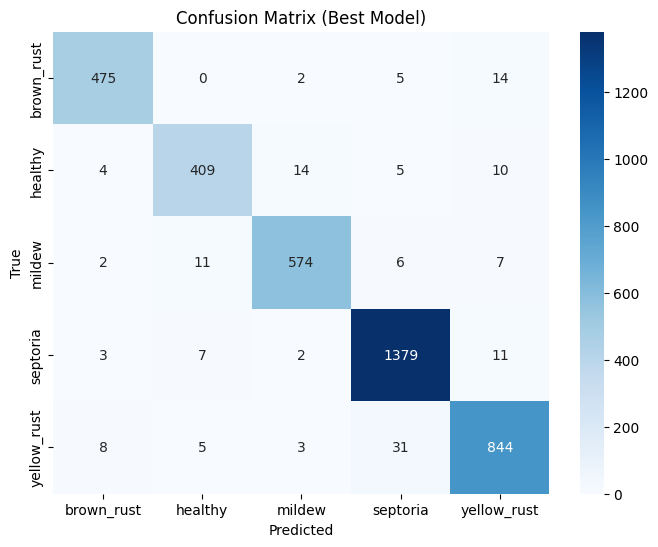

1/1 [==============================] - 0s 20ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.97      0.96      0.96       496
     healthy       0.95      0.93      0.94       442
      mildew       0.97      0.96      0.96       604
    septoria       0.97      0.98      0.98      1397
 yellow_rust       0.95      0.95      0.95       892

    accuracy                           0.96      3831
   macro avg       0.96      0.96      0.96      3831
weighted avg       0.96      0.96      0.96      3831

Best Model - Accuracy Score: 0.9613677890890107


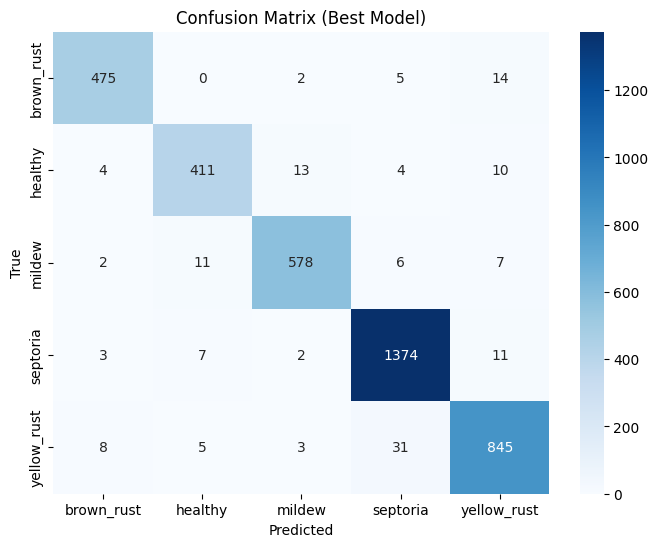

In [5]:
cerealconv_model_128_128_checkpoint = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')

])
build_and_train_model_with_checkpoint(
    dataset_path=dataset_128_128,
    model_architecture=cerealconv_model_128_128_checkpoint,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4,
    model_name="cerealconv_model_128_128_checkpoint"
)

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 256, 256, 64)      1792      
                                                                 
 batch_normalization (BatchN  (None, 256, 256, 64)     256       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 256, 256, 64)      36928     
                                                                 
 batch_normalization_1 (Batc  (None, 256, 256, 64)     256       
 hNormalization)                                                 
                                                                 
 max_pooling2d (MaxPooling2D  (None, 12

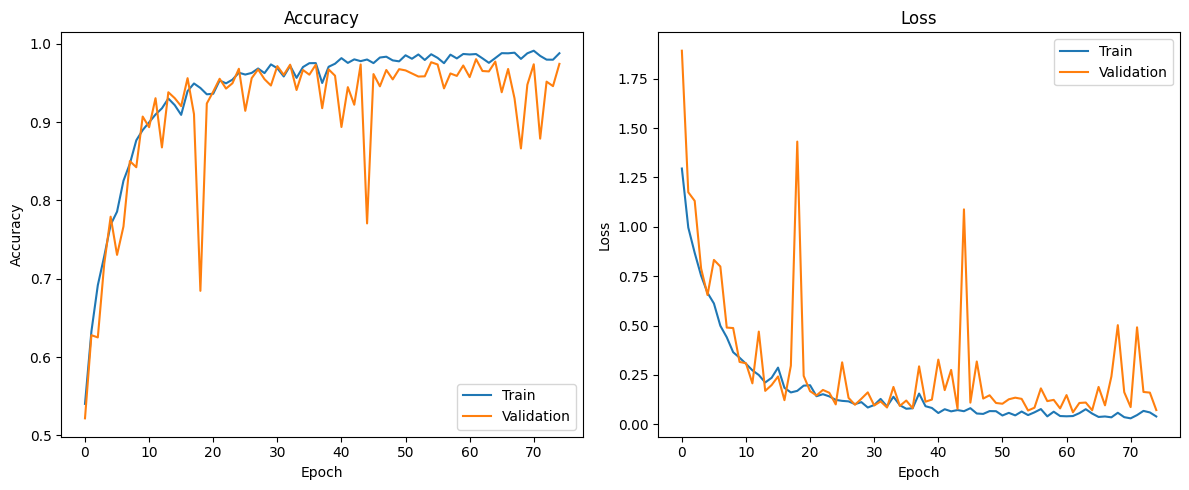

1/1 [==============================] - 0s 24ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.98      0.98      0.98       496
     healthy       0.97      0.95      0.96       442
      mildew       0.98      0.97      0.98       600
    septoria       0.99      0.98      0.98      1402
 yellow_rust       0.96      0.99      0.97       891

    accuracy                           0.98      3831
   macro avg       0.98      0.98      0.98      3831
weighted avg       0.98      0.98      0.98      3831

Final Model - Accuracy Score: 0.97755155311929


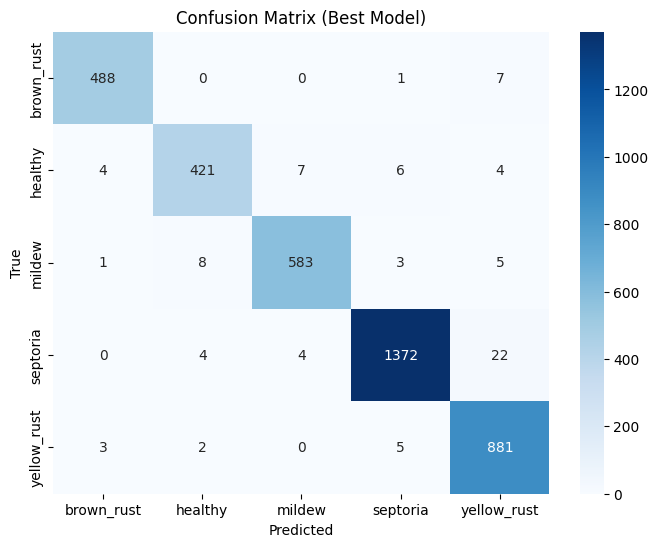

1/1 [==============================] - 0s 21ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.98      0.98      0.98       496
     healthy       0.97      0.95      0.96       442
      mildew       0.98      0.97      0.98       604
    septoria       0.99      0.98      0.98      1397
 yellow_rust       0.96      0.99      0.97       892

    accuracy                           0.98      3831
   macro avg       0.98      0.98      0.98      3831
weighted avg       0.98      0.98      0.98      3831

Best Model - Accuracy Score: 0.9778125815713913


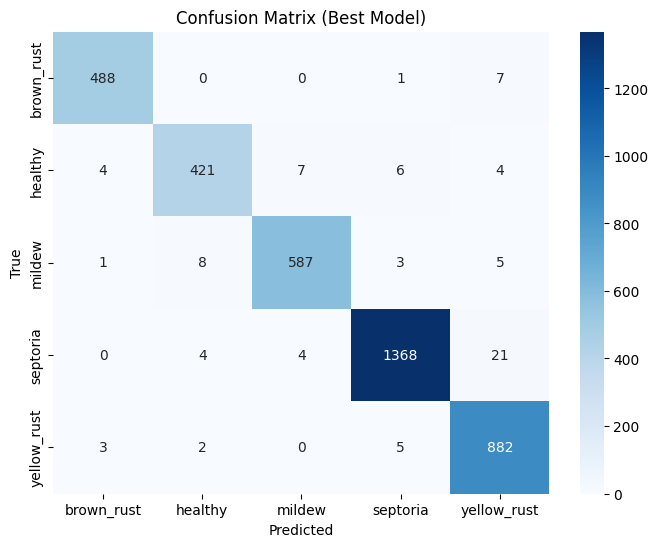

In [5]:
cerealconv_model_checkpoint_data_augmentation = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(256, 256, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')

])

build_and_train_model_with_checkpoint_data_augmentation(
    dataset_path=dataset_256_256,
    model_architecture=cerealconv_model_checkpoint_data_augmentation,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4,
    model_name="cerealconv_model_checkpoint_data_augmentation"
)

### Very Basic Model with few layers
Additional Settings:
- Image Resolution: 128x128
- Batch Size: 9
- Epoch: 75
- Learning Rate: 1e-4

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 64)      1792      
                                                                 
 batch_normalization (BatchN  (None, 128, 128, 64)     256       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 64)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 128)       73856     
                                                                 
 batch_normalization_1 (Batc  (None, 64

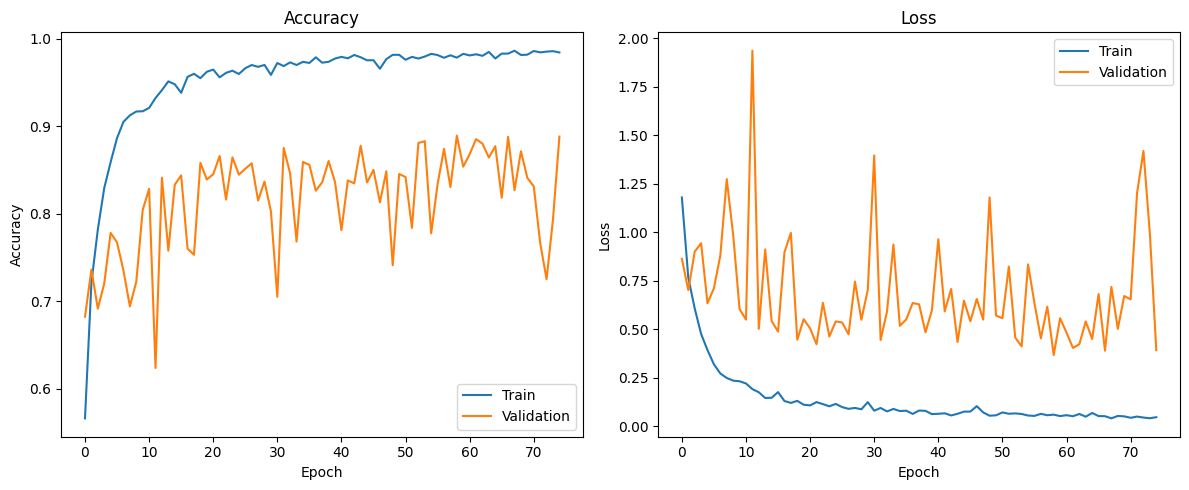

1/1 [==============================] - 0s 18ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.89      0.88      0.89       496
     healthy       0.83      0.92      0.87       442
      mildew       0.91      0.90      0.91       600
    septoria       0.93      0.92      0.92      1402
 yellow_rust       0.87      0.86      0.87       891

    accuracy                           0.90      3831
   macro avg       0.89      0.89      0.89      3831
weighted avg       0.90      0.90      0.90      3831

Final Model - Accuracy Score: 0.896110676063691


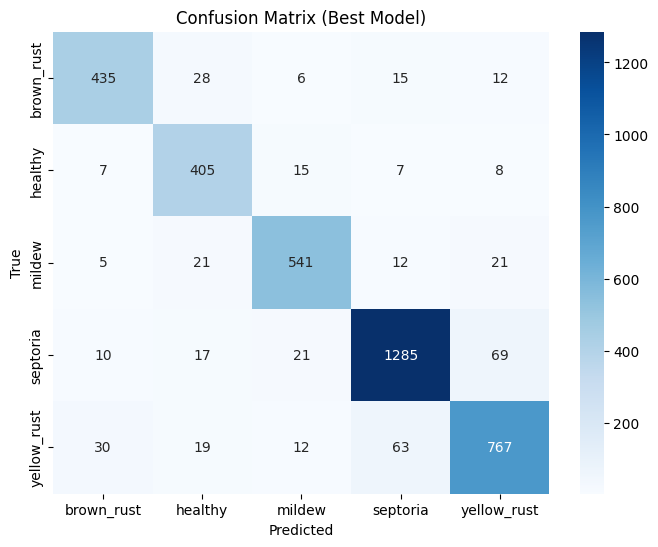

1/1 [==============================] - 0s 18ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.89      0.88      0.89       496
     healthy       0.83      0.92      0.87       442
      mildew       0.91      0.90      0.91       604
    septoria       0.93      0.92      0.92      1397
 yellow_rust       0.88      0.86      0.87       892

    accuracy                           0.90      3831
   macro avg       0.89      0.89      0.89      3831
weighted avg       0.90      0.90      0.90      3831

Best Model - Accuracy Score: 0.896110676063691


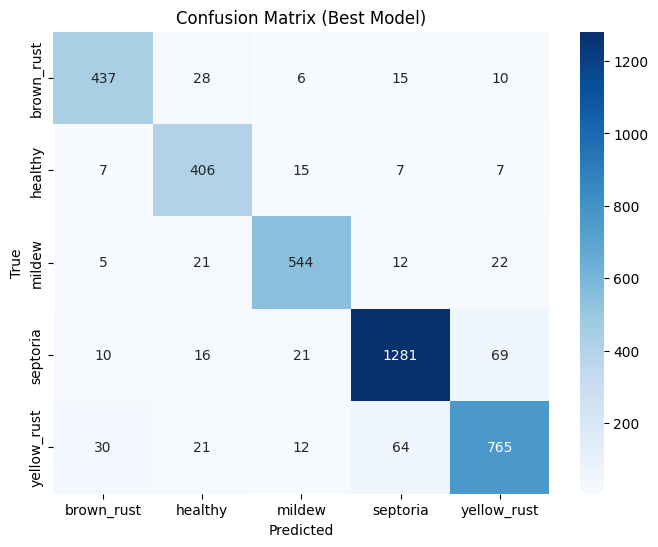

In [5]:
model1_checkpoint = models.Sequential([
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(5, activation='softmax')
    ])

try:
    build_and_train_model_with_checkpoint(
    dataset_path=dataset_128_128,
    model_architecture=model1_checkpoint,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4,
    model_name="model1_checkpoint"
)
except Exception as e:
    print(e)
    send_telegram("Model training failed. ❌\n Error: " + str(e))

### CerealConv model
Additional Settings:
- Image Resolution: 128x128
- Batch_size: 16
- Epochs 75
- Learning_rate 1e-4

Note: Basic CerealConv model with increased batch size in order to test if the increased batch size would stabilise the model and potentially imporve the results. When trying to just increase the batch size with full resolution the machines at our disposal were not capable of allocating the necessary VRAM to train the base cerealconv model with increased batch size.

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 64)      1792      
                                                                 
 batch_normalization (BatchN  (None, 128, 128, 64)     256       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 128, 128, 64)      36928     
                                                                 
 batch_normalization_1 (Batc  (None, 128, 128, 64)     256       
 hNormalization)                                                 
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64

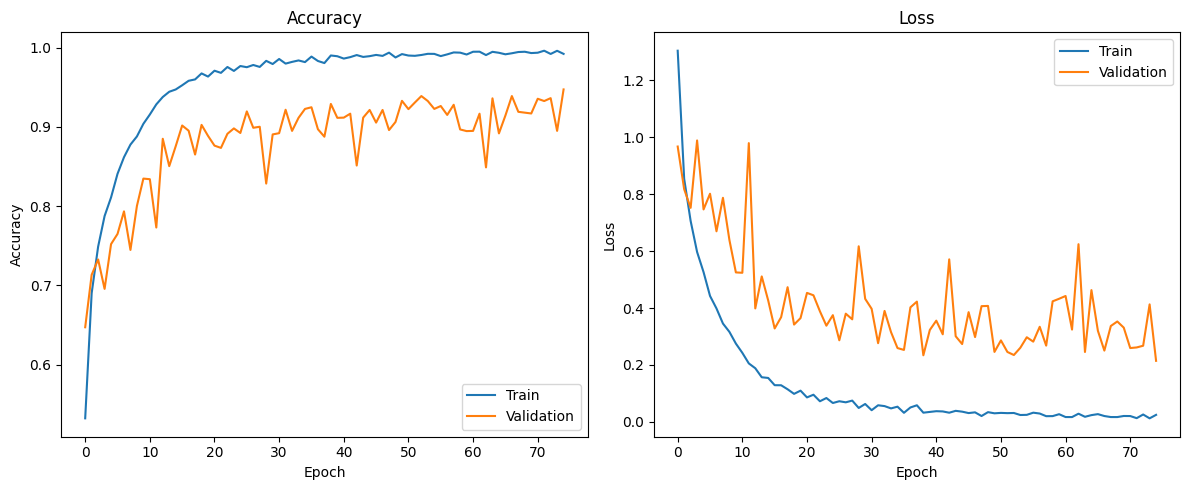

1/1 [==============================] - 0s 19ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.95      0.95      0.95       496
     healthy       0.91      0.93      0.92       443
      mildew       0.96      0.94      0.95       603
    septoria       0.95      0.96      0.96      1401
 yellow_rust       0.93      0.92      0.93       896

    accuracy                           0.94      3839
   macro avg       0.94      0.94      0.94      3839
weighted avg       0.94      0.94      0.94      3839

Final Model - Accuracy Score: 0.9426934097421203


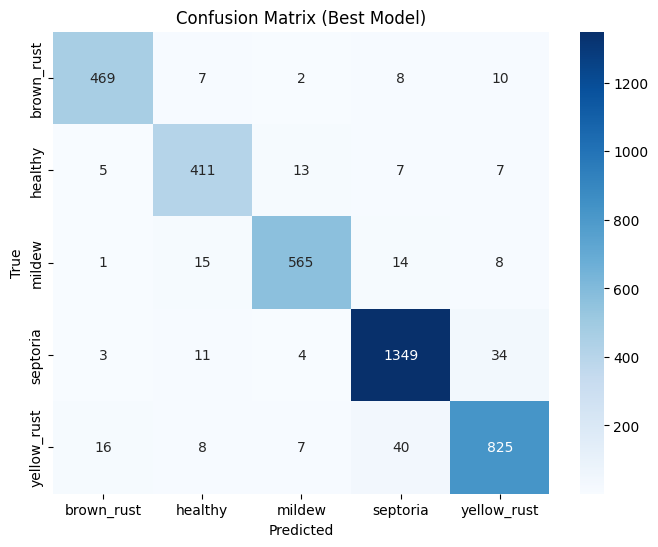

1/1 [==============================] - 0s 20ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.94      0.95      0.95       499
     healthy       0.91      0.93      0.92       444
      mildew       0.96      0.94      0.95       600
    septoria       0.95      0.96      0.96      1405
 yellow_rust       0.93      0.92      0.93       891

    accuracy                           0.94      3839
   macro avg       0.94      0.94      0.94      3839
weighted avg       0.94      0.94      0.94      3839

Best Model - Accuracy Score: 0.9424329252409481


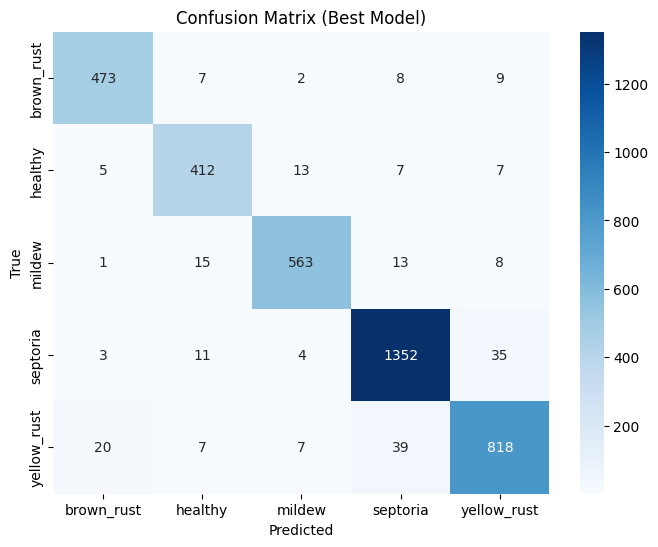

In [5]:
model2_checkpoint = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')

])

try:
    build_and_train_model_with_checkpoint(
    dataset_path=dataset_128_128,
    model_architecture=model2_checkpoint,
    batch_size=16,
    epochs=75,
    learning_rate=1e-4,
    model_name="model2_checkpoint"
)
except Exception as e:
    print(e)
    send_telegram("Model training failed. ❌\n Error: " + str(e))

### CerealConv model
Additional Settings:
- Image Resolution: 256x256
- Batch_size: 4
- Epochs 200
- Learning_rate 5e-5

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 256, 256, 64)      1792      
                                                                 
 batch_normalization (BatchN  (None, 256, 256, 64)     256       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 256, 256, 64)      36928     
                                                                 
 batch_normalization_1 (Batc  (None, 256, 256, 64)     256       
 hNormalization)                                                 
                                                                 
 max_pooling2d (MaxPooling2D  (None, 12

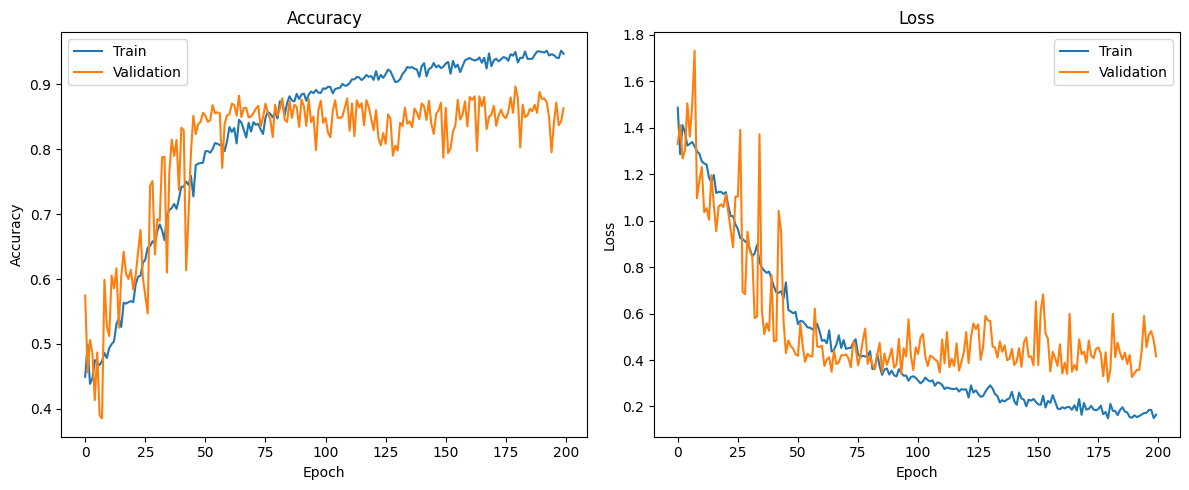

1/1 [==============================] - 0s 20ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.93      0.89      0.91       492
     healthy       0.86      0.83      0.85       441
      mildew       0.86      0.91      0.88       602
    septoria       0.94      0.91      0.92      1404
 yellow_rust       0.87      0.92      0.90       892

    accuracy                           0.90      3831
   macro avg       0.89      0.89      0.89      3831
weighted avg       0.90      0.90      0.90      3831

Final Model - Accuracy Score: 0.8992430174889063


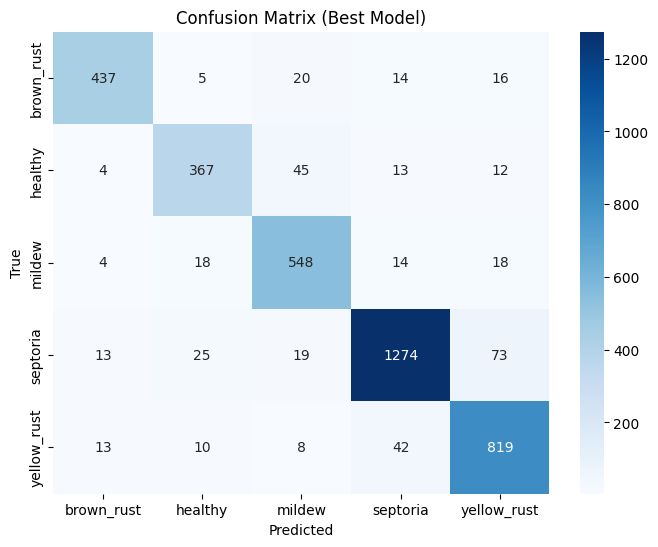

1/1 [==============================] - 0s 20ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.93      0.89      0.91       495
     healthy       0.86      0.83      0.85       442
      mildew       0.85      0.91      0.88       600
    septoria       0.94      0.91      0.92      1404
 yellow_rust       0.87      0.92      0.89       890

    accuracy                           0.90      3831
   macro avg       0.89      0.89      0.89      3831
weighted avg       0.90      0.90      0.90      3831

Best Model - Accuracy Score: 0.8984599321326024


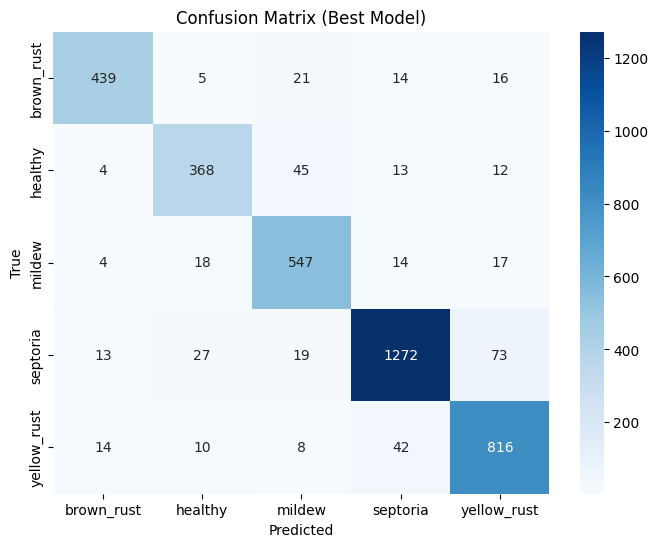

In [5]:
model3_checkpoint = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(256, 256, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')

])

try:
    build_and_train_model_with_checkpoint(dataset_path=dataset_256_256, model_architecture=model3_checkpoint, batch_size=4, epochs=200, learning_rate=5e-5, model_name="model3_checkpoint")
except Exception as e:
    print(e)
    send_telegram("Model training failed. ❌\n Error: " + str(e))

### Very Basic CNN + ViT
Additional Settings:
- Image Resolution: 256x256
- Batch_size: 8
- Epochs 75
- Learning_rate 1e-4

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 64  1792        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256,

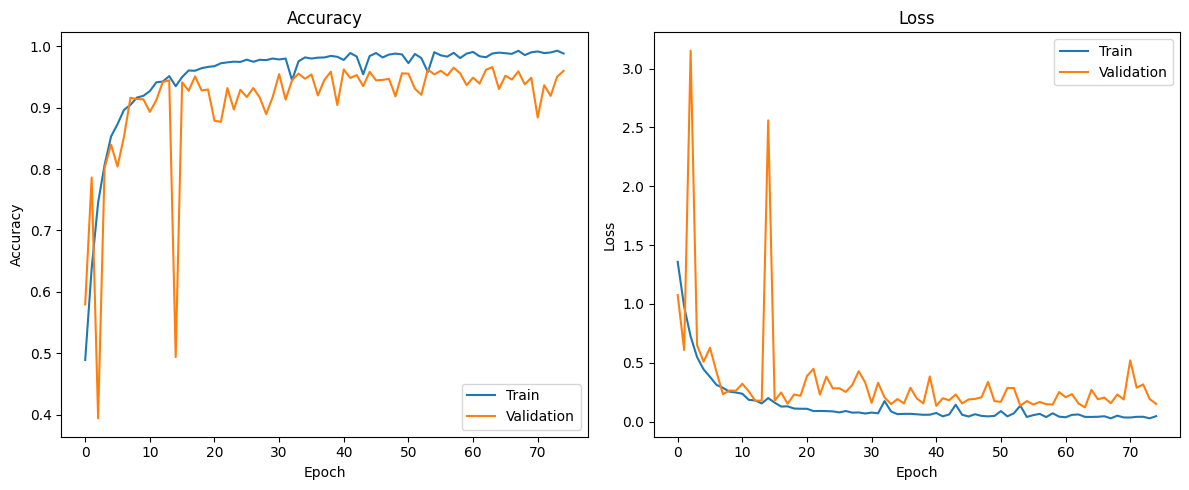

1/1 [==============================] - 0s 49ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.98      0.97      0.98       496
     healthy       0.96      0.95      0.96       442
      mildew       0.96      0.97      0.97       600
    septoria       0.98      0.98      0.98      1402
 yellow_rust       0.96      0.96      0.96       891

    accuracy                           0.97      3831
   macro avg       0.97      0.97      0.97      3831
weighted avg       0.97      0.97      0.97      3831

Final Model - Accuracy Score: 0.971025841816758


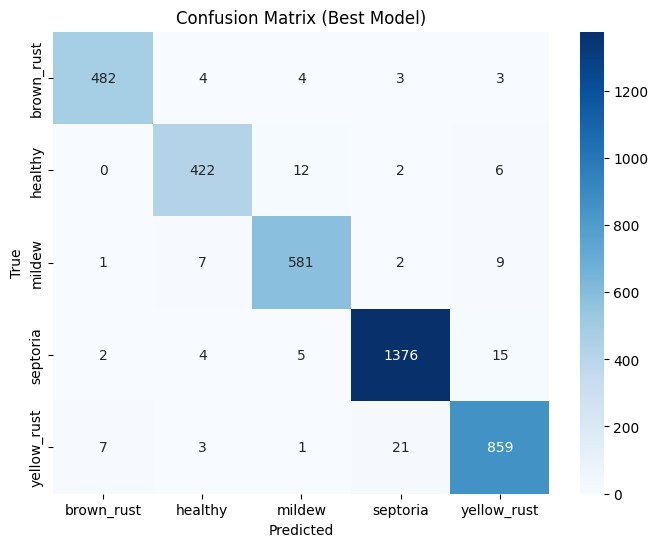

1/1 [==============================] - 0s 49ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.98      0.97      0.98       496
     healthy       0.96      0.95      0.96       442
      mildew       0.96      0.97      0.97       604
    septoria       0.98      0.98      0.98      1397
 yellow_rust       0.96      0.96      0.96       892

    accuracy                           0.97      3831
   macro avg       0.97      0.97      0.97      3831
weighted avg       0.97      0.97      0.97      3831

Best Model - Accuracy Score: 0.9707648133646567


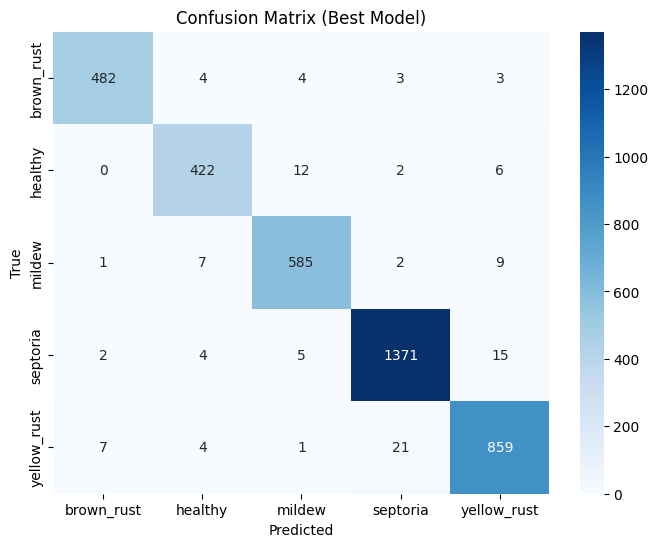

In [ ]:
def build_cnn_vit_model(input_shape=(256, 256, 3), num_classes=5):
    inputs = tf.keras.Input(shape=input_shape)

    # CNN Backbone
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    # Reshape for Transformer: (B, H, W, C) -> (B, N_patches, C)
    h, w, c = x.shape[1:]
    num_patches = h * w
    x = layers.Reshape((num_patches, c))(x)

    # Positional Embedding
    pos_embed = layers.Embedding(input_dim=num_patches, output_dim=c)
    positions = tf.range(start=0, limit=num_patches, delta=1)
    x = x + pos_embed(positions)

    # Transformer Encoder
    for _ in range(2):  # Two transformer blocks
        # LayerNorm -> MultiHeadAttention -> Skip connection
        x1 = layers.LayerNormalization(epsilon=1e-6)(x)
        attention_output = layers.MultiHeadAttention(num_heads=4, key_dim=c)(x1, x1)
        x2 = layers.Add()([x, attention_output])

        # MLP
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        mlp_output = layers.Dense(c * 2, activation='relu')(x3)
        mlp_output = layers.Dense(c)(mlp_output)
        x = layers.Add()([x2, mlp_output])

    # Classification Head
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    return model

cnn_vit_model1 = build_cnn_vit_model(input_shape=(256,256,3))
build_and_train_model_with_checkpoint(dataset_path=dataset_256_256, model_architecture=cnn_vit_model1, batch_size=8, epochs=75, learning_rate=1e-4, model_name="cnn_vit_model1_checkpoint")

### Small CNN + ViT
Additional Settings:
- Image Resolution: 256x256
- Batch_size: 8
- Epochs 75
- Learning_rate 1e-4

In [5]:
def build_cnn_vit_model2():
    inputs = tf.keras.Input(shape=(256, 256, 3))

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 1, padding="same")(x)
    h, w, c = x.shape[1:]
    num_patches = h * w
    x = layers.Reshape((num_patches, c))(x)

    positions = tf.range(start=0, limit=num_patches, delta=1)
    pos_embed = layers.Embedding(input_dim=num_patches, output_dim=c)
    x = x + pos_embed(positions)

    for _ in range(4):
        x1 = layers.LayerNormalization()(x)
        attn_output = layers.MultiHeadAttention(num_heads=4, key_dim=c)(x1, x1)
        x2 = layers.Add()([x, attn_output])
        x3 = layers.LayerNormalization()(x2)
        mlp = layers.Dense(c * 2, activation='relu')(x3)
        mlp = layers.Dense(c)(mlp)
        x = layers.Add()([x2, mlp])

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Dense(5, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    return model

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_8 (Conv2D)              (None, 256, 256, 64  1792        ['input_2[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_8 (BatchNo  (None, 25

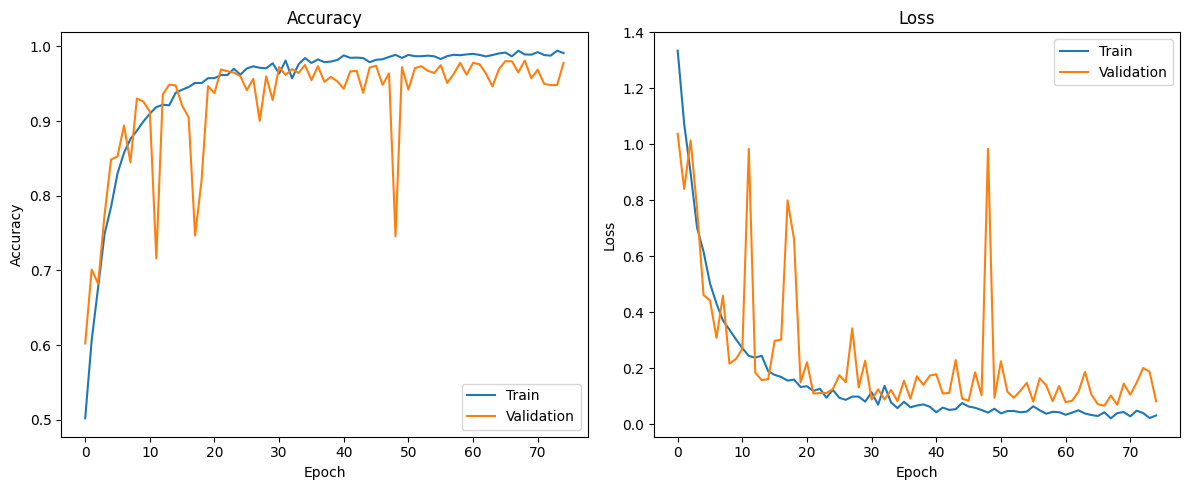

1/1 [==============================] - 0s 76ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.99      0.98      0.99       496
     healthy       0.92      0.99      0.95       442
      mildew       0.99      0.95      0.97       600
    septoria       0.99      0.97      0.98      1402
 yellow_rust       0.97      0.99      0.98       891

    accuracy                           0.98      3831
   macro avg       0.97      0.98      0.97      3831
weighted avg       0.98      0.98      0.98      3831

Final Model - Accuracy Score: 0.9767684677629862


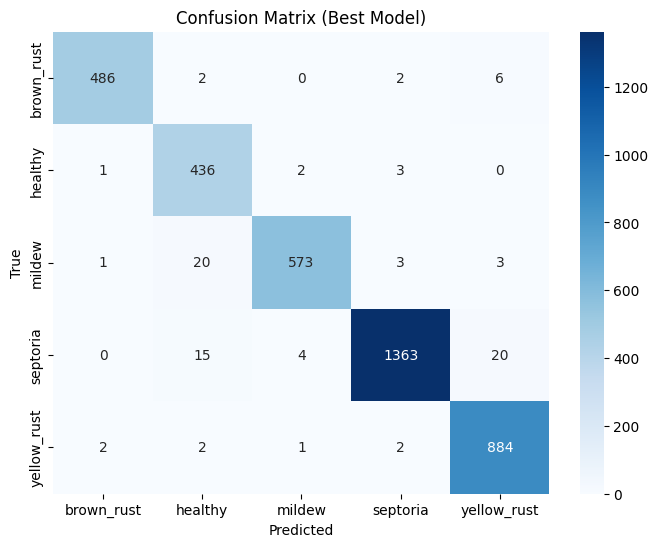

1/1 [==============================] - 0s 76ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.99      0.98      0.99       496
     healthy       0.92      0.99      0.95       442
      mildew       0.99      0.96      0.97       604
    septoria       0.99      0.97      0.98      1397
 yellow_rust       0.97      0.99      0.98       892

    accuracy                           0.98      3831
   macro avg       0.97      0.98      0.97      3831
weighted avg       0.98      0.98      0.98      3831

Best Model - Accuracy Score: 0.9770294962150874


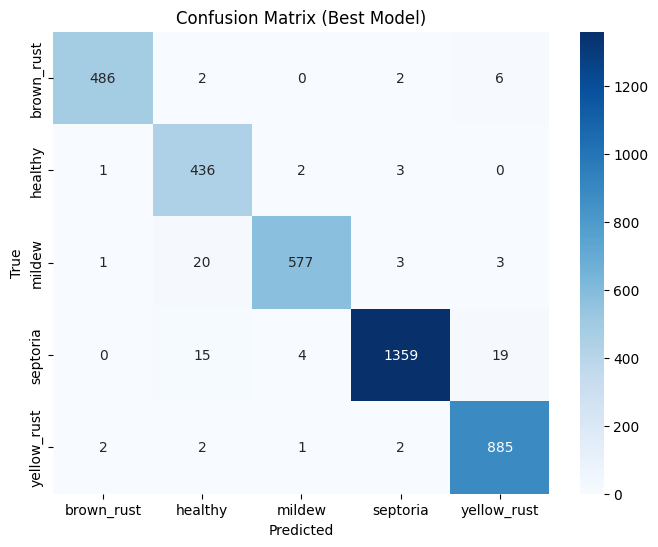

In [ ]:
cnn_vit_model2 = build_cnn_vit_model2()
build_and_train_model_with_checkpoint(
    dataset_path=dataset_256_256,
    model_architecture=cnn_vit_model2,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4,
    model_name="cnn_vit_model2_checkpoint"
)

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 64  1792        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256,

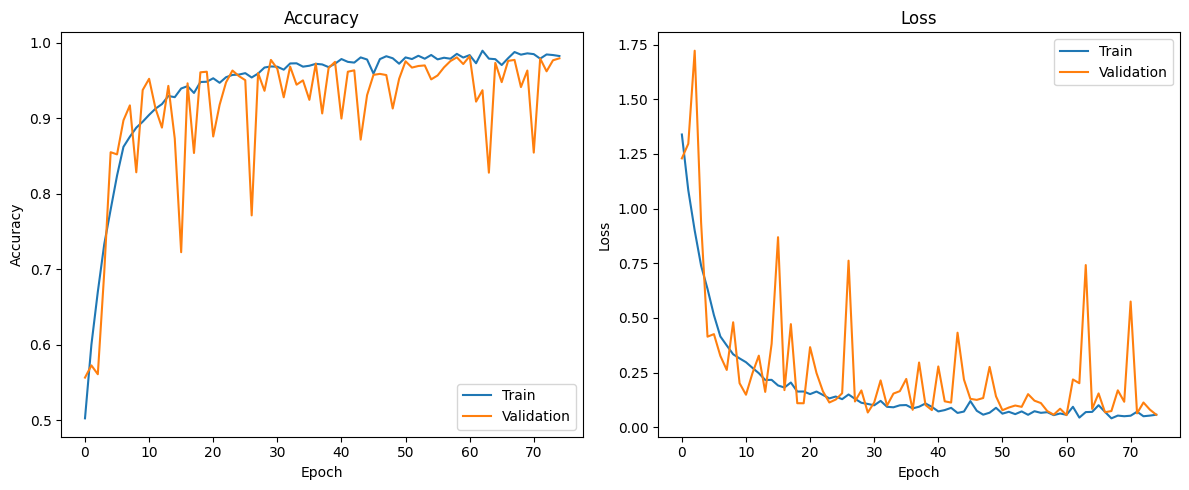

1/1 [==============================] - 0s 79ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.99      0.98      0.99       496
     healthy       0.95      0.98      0.96       442
      mildew       0.99      0.95      0.97       600
    septoria       0.99      0.99      0.99      1402
 yellow_rust       0.98      0.98      0.98       891

    accuracy                           0.98      3831
   macro avg       0.98      0.98      0.98      3831
weighted avg       0.98      0.98      0.98      3831

Final Model - Accuracy Score: 0.9812059514487079


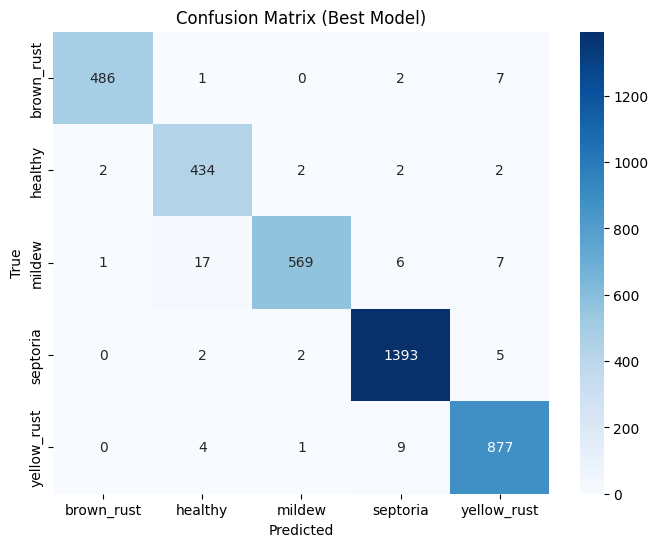

1/1 [==============================] - 0s 84ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.99      0.98      0.99       496
     healthy       0.95      0.98      0.96       442
      mildew       0.99      0.95      0.97       604
    septoria       0.99      0.99      0.99      1397
 yellow_rust       0.98      0.98      0.98       892

    accuracy                           0.98      3831
   macro avg       0.98      0.98      0.98      3831
weighted avg       0.98      0.98      0.98      3831

Best Model - Accuracy Score: 0.9812059514487079


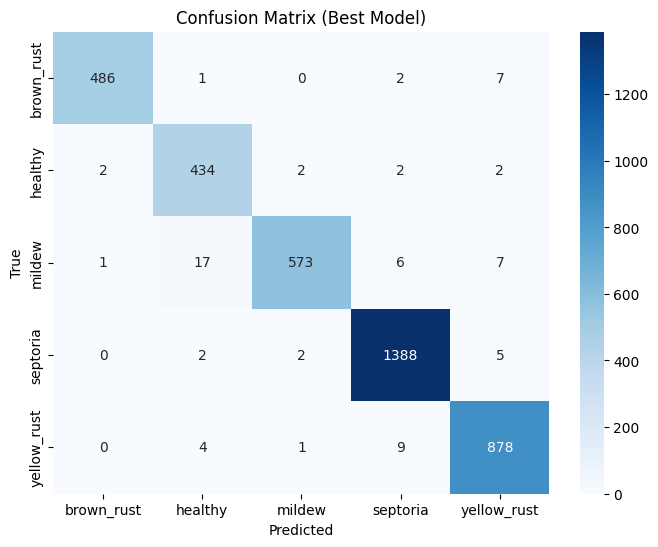

In [ ]:
cnn_vit_model2_data_augmentation = build_cnn_vit_model2()
build_and_train_model_with_checkpoint_data_augmentation(
    dataset_path=dataset_256_256,
    model_architecture=cnn_vit_model2_data_augmentation,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4,
    model_name="cnn_vit_model2_data_augmentation_checkpoint"
)

### CerealConv + ViT
Additional Settings:
- Image Resolution: 256x256
- Batch_size: 8
- Epochs 75
- Learning_rate 1e-4

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_14 (Conv2D)             (None, 256, 256, 64  1792        ['input_2[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_14 (BatchN  (None, 25

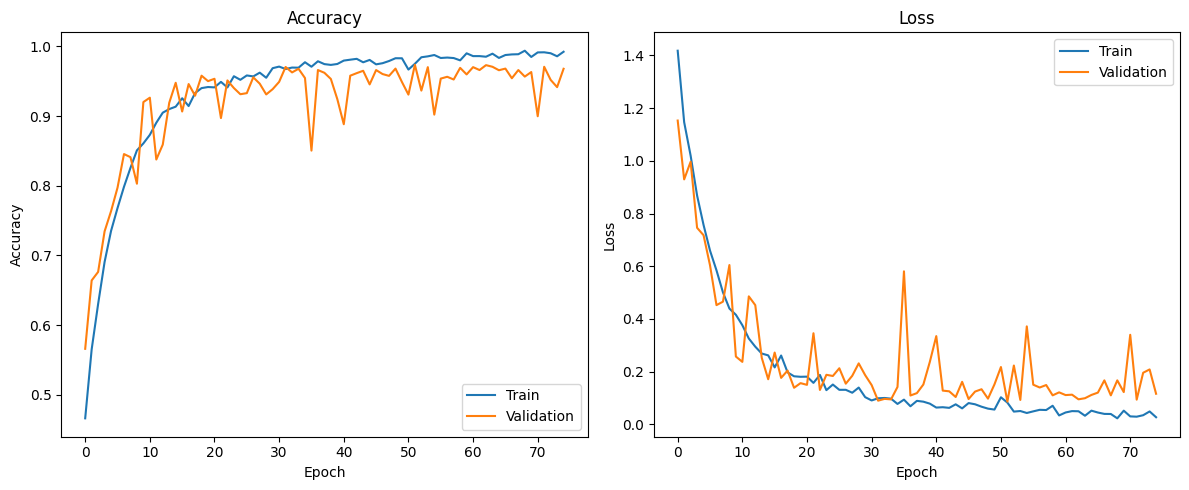

1/1 [==============================] - 0s 66ms/step
Final Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.99      0.97      0.98       496
     healthy       0.94      0.97      0.95       442
      mildew       0.98      0.96      0.97       600
    septoria       0.99      0.97      0.98      1402
 yellow_rust       0.95      0.98      0.96       891

    accuracy                           0.97      3831
   macro avg       0.97      0.97      0.97      3831
weighted avg       0.97      0.97      0.97      3831

Final Model - Accuracy Score: 0.9712868702688593


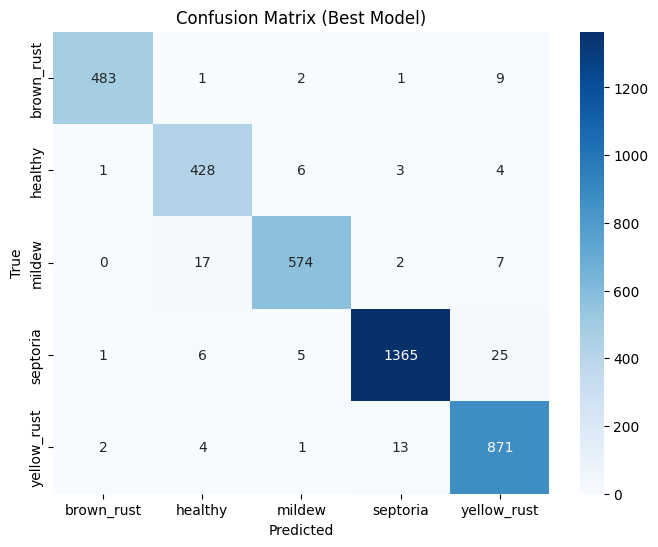

1/1 [==============================] - 0s 56ms/step
Best Model - Classification Report:
               precision    recall  f1-score   support

  brown_rust       0.99      0.97      0.98       496
     healthy       0.94      0.97      0.95       442
      mildew       0.98      0.96      0.97       604
    septoria       0.99      0.97      0.98      1397
 yellow_rust       0.95      0.98      0.96       892

    accuracy                           0.97      3831
   macro avg       0.97      0.97      0.97      3831
weighted avg       0.97      0.97      0.97      3831

Best Model - Accuracy Score: 0.9715478987209606


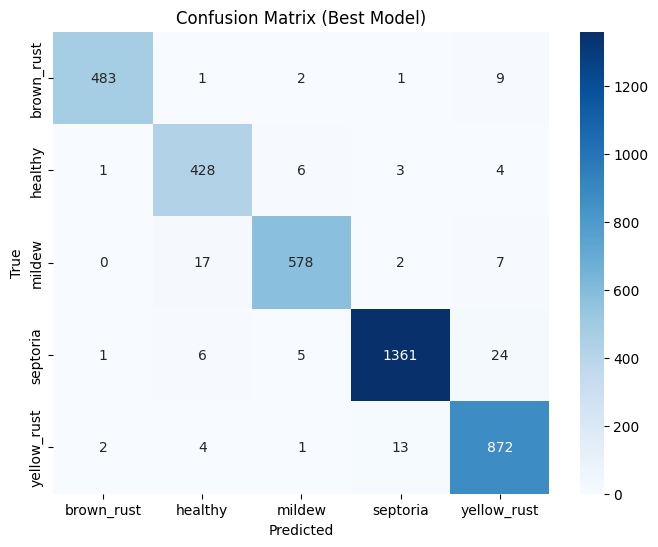

In [ ]:
def build_cnn_vit_model3():
    inputs = tf.keras.Input(shape=(256, 256, 3))

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(512, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(512, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(512, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 1, padding="same")(x)
    h, w, c = x.shape[1:]
    num_patches = h * w
    x = layers.Reshape((num_patches, c))(x)

    positions = tf.range(start=0, limit=num_patches, delta=1)
    pos_embed = layers.Embedding(input_dim=num_patches, output_dim=c)
    x = x + pos_embed(positions)

    for _ in range(4):
        x1 = layers.LayerNormalization()(x)
        attn_output = layers.MultiHeadAttention(num_heads=4, key_dim=c)(x1, x1)
        x2 = layers.Add()([x, attn_output])
        x3 = layers.LayerNormalization()(x2)
        mlp = layers.Dense(c * 2, activation='relu')(x3)
        mlp = layers.Dense(c)(mlp)
        x = layers.Add()([x2, mlp])

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Dense(5, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    return model

cnn_vit_model3 = build_cnn_vit_model3()
build_and_train_model_with_checkpoint(
    dataset_path=dataset_256_256,
    model_architecture=cnn_vit_model3,
    batch_size=8,
    epochs=75,
    learning_rate=1e-4,
    model_name="cnn_vit_model3_checkpoint"
)